# Set up 

In [5]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [8]:
import sys
import os
import os.path as op

sys.path.append(op.abspath(""))  

# Load FSL inside Neurodesk (as in the labs)
import module as lmod
await lmod.purge(force=True)
await lmod.load('fsl/6.0.7.18')
await lmod.list()

from utils import *          # utils.py copied from labs 
def loadFSL():
    """
    Function to load FSL 6.0.7.18 module
    Ensures proper environment variables are setup.
    This function should be called at the start of any
    notebook which relies in any capacity on FSL.
    
    If you wish to change the FSL version being used,
    you should edit within the load AND FSLDIR the version.
    Make sure it exists in the neurodocker image before changing it!
    """
    import asyncio
    import os
    # We need to do the import asynchronously, as modules rely on await within
    #asyncio.run(importFSLasync())
    os.environ["FSLDIR"]="/cvmfs/neurodesk.ardc.edu.au/containers/fsl_6.0.7.18_20250928/fsl_6.0.7.18_20250928.simg/opt/fsl-6.0.7.18/"
    os.environ["FSLOUTPUTTYPE"]="NIFTI_GZ"
    os.environ["SINGULARITY_BINDPATH"]="/data,/neurodesktop-storage,/tmp,/cvmfs"


loadFSL()
os.environ["FSLOUTPUTTYPE"] = "NIFTI_GZ"   # every FSL output as .nii.gz

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from nilearn import plotting, image

from helpers import (find_one, check_tools, run, needs, describe,
                     center_of_mass_world, tissue_volumes, spatial_corr, save_fig)

check_tools("fslreorient2std", "bet", "fast", "flirt", "fnirt", "applywarp")

FSLDIR = /cvmfs/neurodesk.ardc.edu.au/containers/fsl_6.0.7.18_20250928/fsl_6.0.7.18_20250928.simg/opt/fsl-6.0.7.18/
All tools found: fslreorient2std, bet, fast, flirt, fnirt, applywarp


In [9]:
FORCE = False   # True = recompute every step even if its outputs already exist
ANAT_KW = dict(draw_cross=False, colorbar=False)   # common style for brain figures

PROJECT_ROOT = op.abspath("")      
DATA_DIR = op.join(PROJECT_ROOT, "data")
ANAT_DIR = op.join(PROJECT_ROOT, "derivatives", "anat")
FUNC_DIR = op.join(PROJECT_ROOT, "derivatives", "func")
GLM_DIR = op.join(PROJECT_ROOT, "derivatives", "glm")
STAT_DIR = op.join(GLM_DIR, "statistical_maps")
FIG_DIR  = op.join(PROJECT_ROOT, "figures")
GLM_FIG_DIR = op.join(FIG_DIR,'GLM')
for d in (ANAT_DIR, FUNC_DIR, GLM_DIR, STAT_DIR, FIG_DIR, GLM_FIG_DIR):
    os.makedirs(d, exist_ok=True)

# Raw data (searched recursively)
T1_RAW   = find_one(DATA_DIR, "T1w.nii.gz")
FMRI_RAW = find_one(DATA_DIR, "tfMRI_LANGUAGE_LR.nii.gz")
EVENTS   = find_one(DATA_DIR, "tfMRI_LANGUAGE_LR_task_onsets.csv")

for p in (T1_RAW, FMRI_RAW, EVENTS):
    print(op.relpath(p, PROJECT_ROOT))

data/T1-20261104T214726Z-1-001/T1/T1w.nii.gz
data/fMRI-20261104T213034Z-1-001/fMRI/tfMRI_LANGUAGE_LR/tfMRI_LANGUAGE_LR.nii.gz
data/fMRI-20261104T213034Z-1-001/fMRI/tfMRI_LANGUAGE_LR/tfMRI_LANGUAGE_LR_task_onsets.csv


In [10]:
events = pd.read_csv(EVENTS)
events.head(10)

,onset,duration,trial_type
0,0.241,28.270,story
1,0.241,20.445,present_story
2,21.192,1.161,question_story
3,25.550,2.961,response_story
4,28.696,0.727,cue
5,30.095,5.667,present_math
6,30.095,12.241,math
7,35.946,3.391,question_math
8,39.371,2.965,response_math
9,42.570,5.453,present_math


# 1.3 General Linear Model

The GLM let us fit multiples linear regression models in a model. Matrix formulation :
$X = YB + E$, with $X$ the multivariates observations, $Y$ the design matrix containging conditions and covariates, $B$ the parameter weigths, and $E$ the residual error.

The beta parameters are estimated using Ordinary Least Square (OLS).

### 1.3.a Building experimental design matrix
Building the experimental design matrix of the GLM from the events file. The regressors obtained from the events file are the task-related regressors.

Nuisance regressors: To mitigate any motion artifacts the motion confounds from the previous preprocessing were taken into account (rotation and translation). A cosine drift model was added to account for any drift occurring over time.

In [11]:
from nilearn.glm.first_level import make_first_level_design_matrix, FirstLevelModel

TR = 0.72
FMRI_SMOOTH  = op.join(FUNC_DIR, "tfMRI_LANGUAGE_LR_mc_smooth.nii.gz")
FUNC_MASK    = op.join(FUNC_DIR, "func_brain_mask.nii.gz")
CONFOUNDS    = op.join(FUNC_DIR, "func_motion_confounds.csv")
motion = pd.read_csv(CONFOUNDS)

# Specification of GLM
fmri_glm = FirstLevelModel(t_r=TR, # repetition time
                           mask_img=FUNC_MASK,
                           noise_model='ar1', #first level autoregressive noise model
                           standardize=False,
                           hrf_model='spm', #hemodynamic response function
                           drift_model='cosine', #account for drift over time
                           high_pass=.01)

# Fit the model to our design and data
fmri_glm = fmri_glm.fit(FMRI_SMOOTH, events,
                        confounds=motion[['rot_x', 'rot_y','rot_z', 'trans_x', 'trans_y', 'trans_z']]) # motion confounds from funct preprocessing

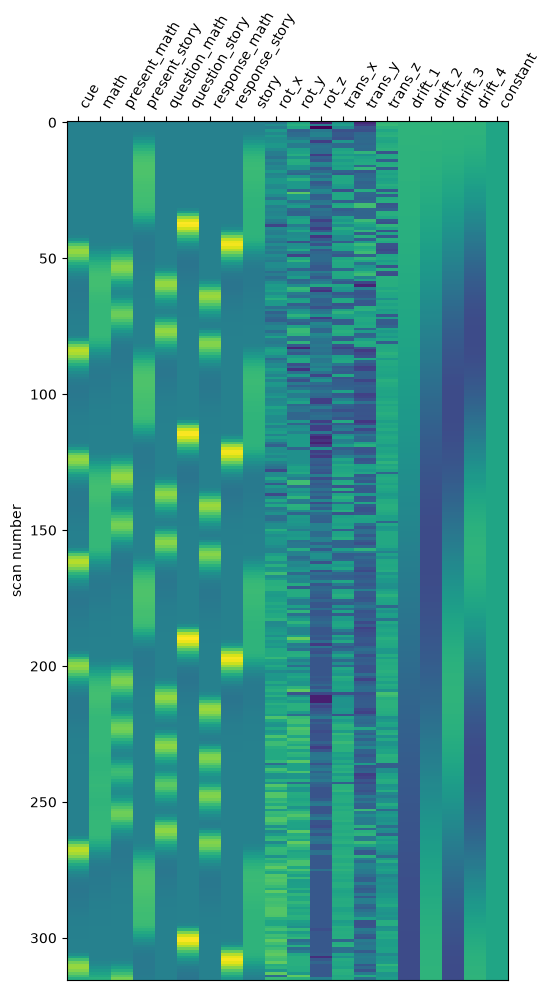

In [12]:
from nilearn.plotting import plot_design_matrix

design_mat = fmri_glm.design_matrices_[0]
plot_design_matrix(design_mat)

plt.savefig(op.join(GLM_FIG_DIR, "design_matrix.png"), dpi=300, bbox_inches="tight")
plt.show()

### 1.3.b Correlation matrix between regressors
It is necessary to look at the correlation between regressors as highly correlated regressors result in unstable estimations of the betas. In the case of exact collinearity the GLM is unable to be fitted. 

With the design matrix specified previously the task specific regressors are more correlected amongst themseleves with the "math" regressor positively correlated with math-related regressors and negatively correlated with story-related regressors, and inveresly. These results are expected, 'math' and 'story' incompasse their respective present, question and response. To be exact, the regressors that might be dangerously correlated are math&present_math(~0.75), story&present_story(~0.75), and math-story (negatively, ~-0.8). 

The motion covariates are almost uncorrelated with the task and drift regressors. Amongst themselves there is some light correlation, with trans_x&rot_y (~0.8) and trans_y&trans_z (~-0.6) the most correlated. The drift covariates are uncorrelated among themselves by construction. 

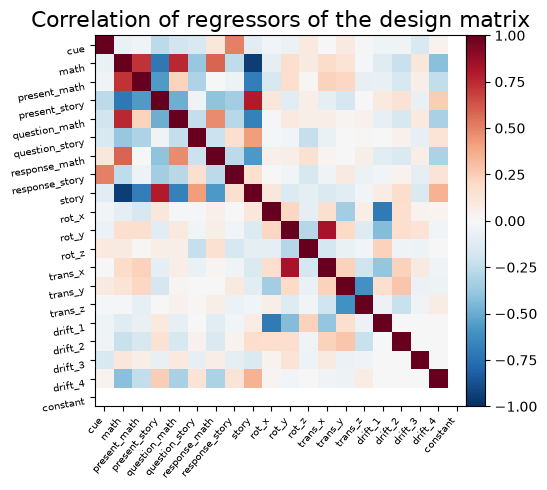

In [13]:
from nilearn.plotting import plot_matrix
columns = ['cue', 'math','present_math','present_story','question_math','question_story','response_math','response_story', 'story']

corr = design_mat.corr()

plot_matrix(corr,title='Correlation of regressors of the design matrix', labels=list(design_mat.columns),vmin=-1, vmax=1, cmap="RdBu_r")


plt.savefig(op.join(GLM_FIG_DIR, "correlation_regressors.png"), dpi=300, bbox_inches="tight")
plt.show()

### (1.3.a) **Adjustment of design matrix**
From the correlation analysis the 'math' and 'story' regressors are discarded as they are too highly correlated to the other regressors to guarantee a stable fit. Such that the **final design matrix** is :

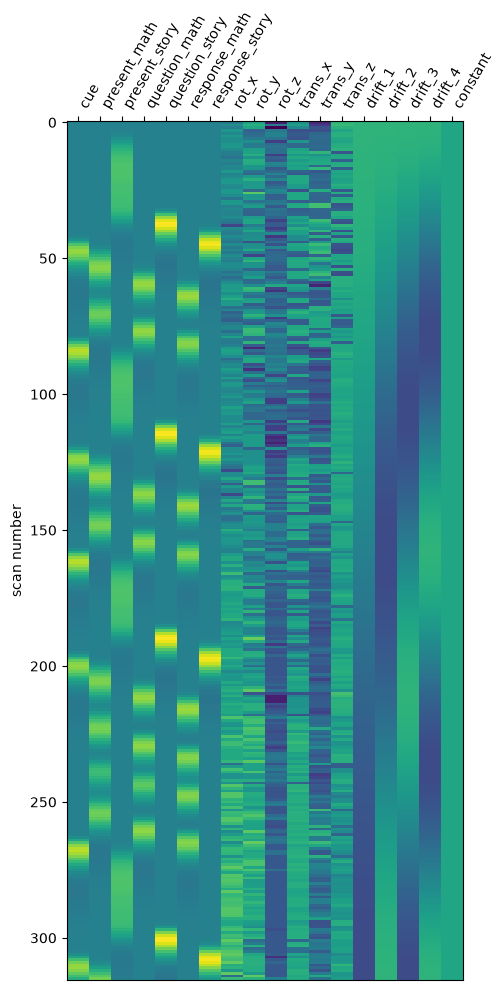

In [14]:
events_clean = events[~events['trial_type'].isin(['story', 'math'])]

# Fit the model to our clean design and data
fmri_glm = fmri_glm.fit(FMRI_SMOOTH, events_clean,
                        confounds=motion[['rot_x','rot_y','rot_z', 'trans_x', 'trans_y', 'trans_z']]) # motion confounds from funct preprocessing

design_mat = fmri_glm.design_matrices_[0]
plot_design_matrix(design_mat)

plt.savefig(op.join(GLM_FIG_DIR, "design_matrix_clean.png"), dpi=300, bbox_inches="tight")
plt.show()

### (1.3.b) Correlation of new design matrix
We now have a correlation matrix with the dangerous correlations removed:

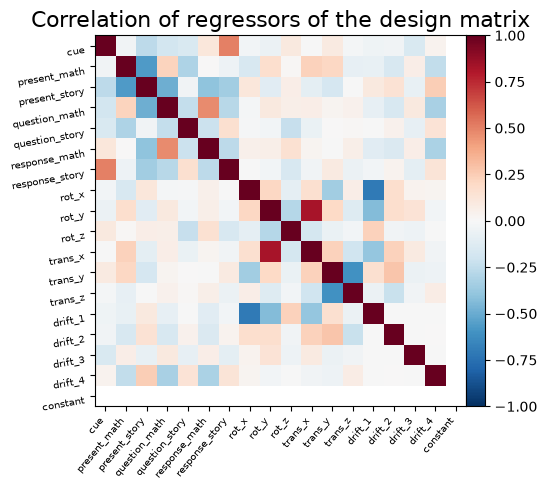

In [15]:
columns_clean = ['cue','present_math','present_story','question_math','question_story','response_math','response_story']

corr = design_mat.corr()

plot_matrix(corr,title='Correlation of regressors of the design matrix', labels=list(design_mat.columns),vmin=-1, vmax=1, cmap="RdBu_r")

plt.savefig(op.join(GLM_FIG_DIR, "correlation_regressors_clean.png"), dpi=300, bbox_inches="tight")
plt.show()

### 1.3.c Statistical maps of task-related regressors
In point 1.3.a) we already runned the GLM at **first level**. We have only one single subject, there is no group level with random effects to control for. 

The task related regressors are the regressors from the event file. To compute their respective statistical maps, computation of the contrast is done with the contrast being the all zero except for a 1 at the index of the corresponding regressor. Positive activation can indicate task-driven activation, negative activation indicates below baseline activation. \
The z_map obtained is corrected (fdr) for multiple statistical tests due to the multiple voxels.

In [16]:
# Task related regressors 
task_reg = ['cue','present_math','present_story','question_math','question_story','response_math','response_story']

design_matrix = fmri_glm.design_matrices_[0]

contrasts = {t: np.eye(design_matrix.shape[1])[design_matrix.columns.get_loc(t)] for t in task_reg} # contrast of each task regressor

z_maps = {name: fmri_glm.compute_contrast(vec, output_type="z_score") for name, vec in contrasts.items()}


Correction for multiple statistical tests.

In [17]:
from nilearn.glm import threshold_stats_img
from nilearn.reporting import get_clusters_table

thresholded, thr = {}, {}
for name, z in z_maps.items():
    thresholded[name], thr[name] = threshold_stats_img(z, alpha=0.05, 
                                                       height_control="fdr", cluster_threshold=10) # correction for multiple voxels
    
    # saving each cluster to csv file
    table = get_clusters_table(z, stat_threshold=thr[name], cluster_threshold=10, two_sided=True)
    table.to_csv(op.join(STAT_DIR, f"{name}_clusters.csv"), index=False)

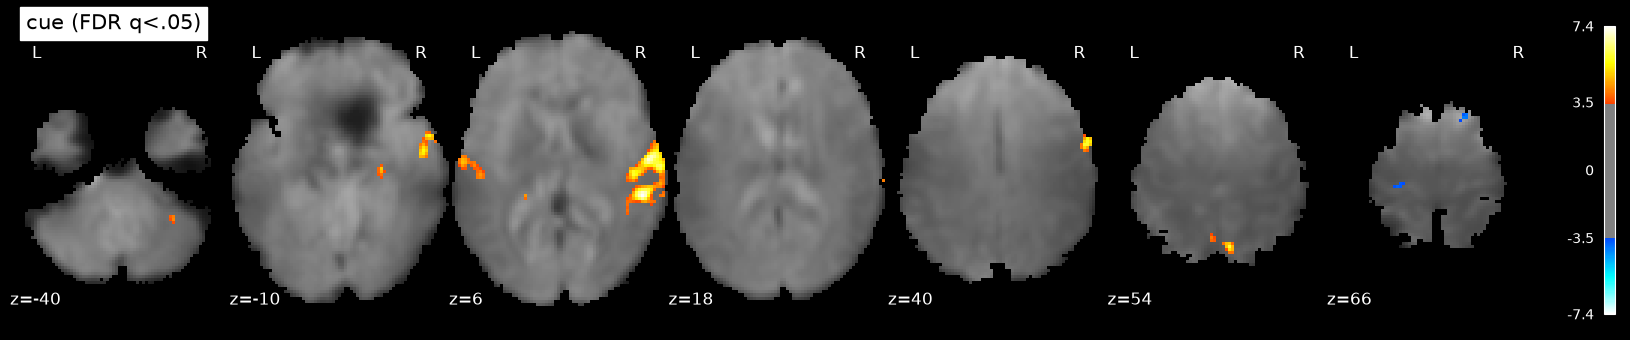

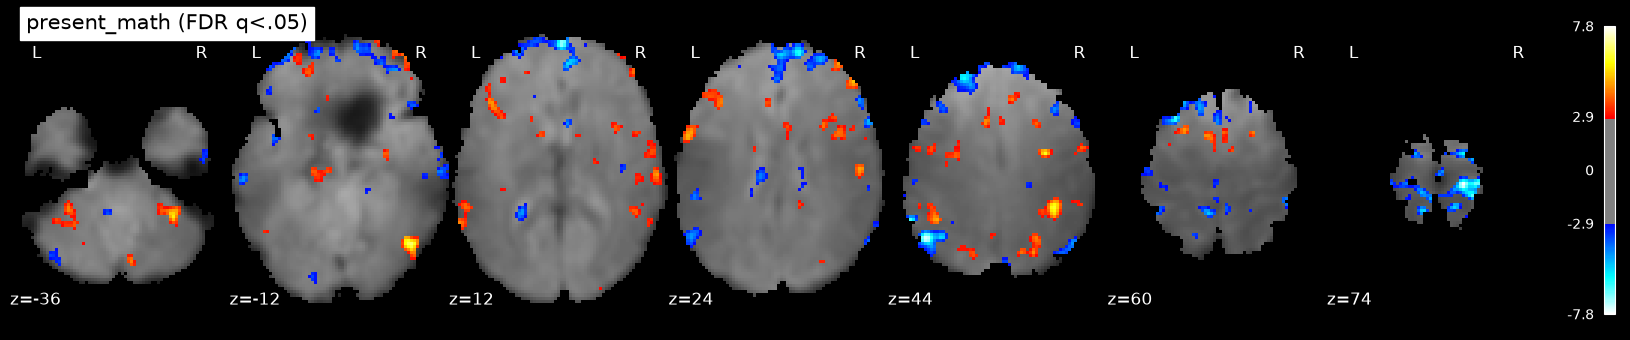

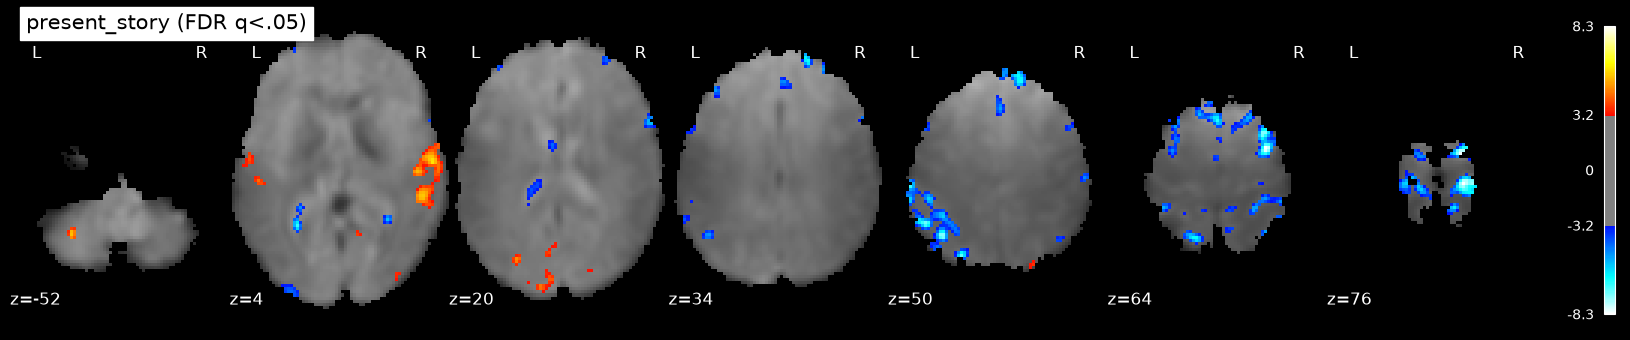

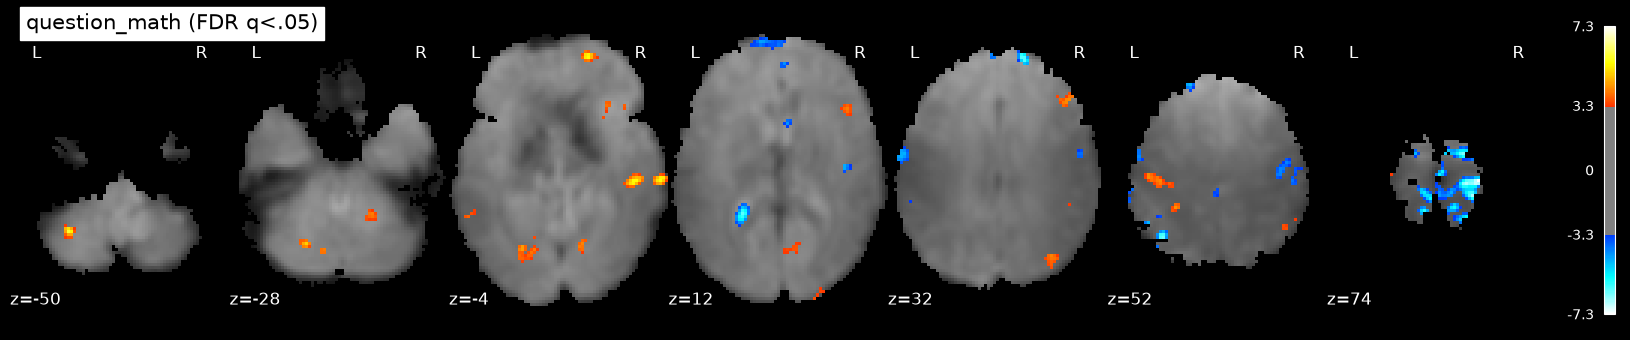

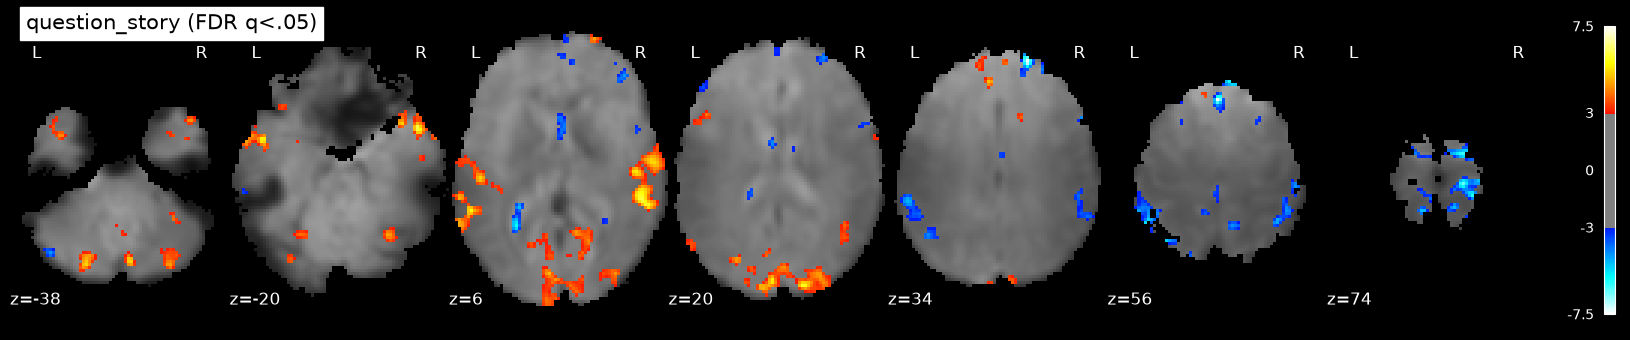

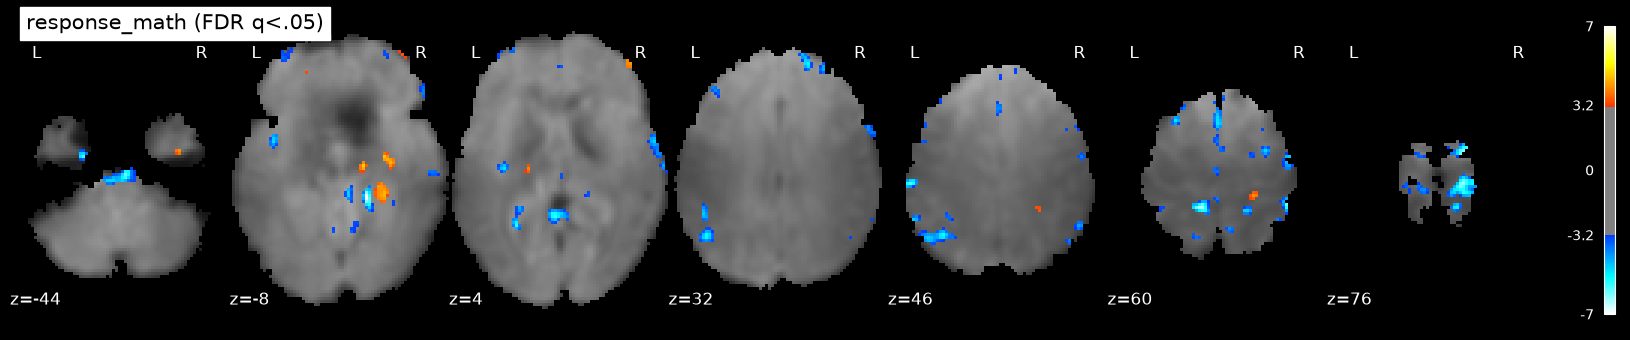

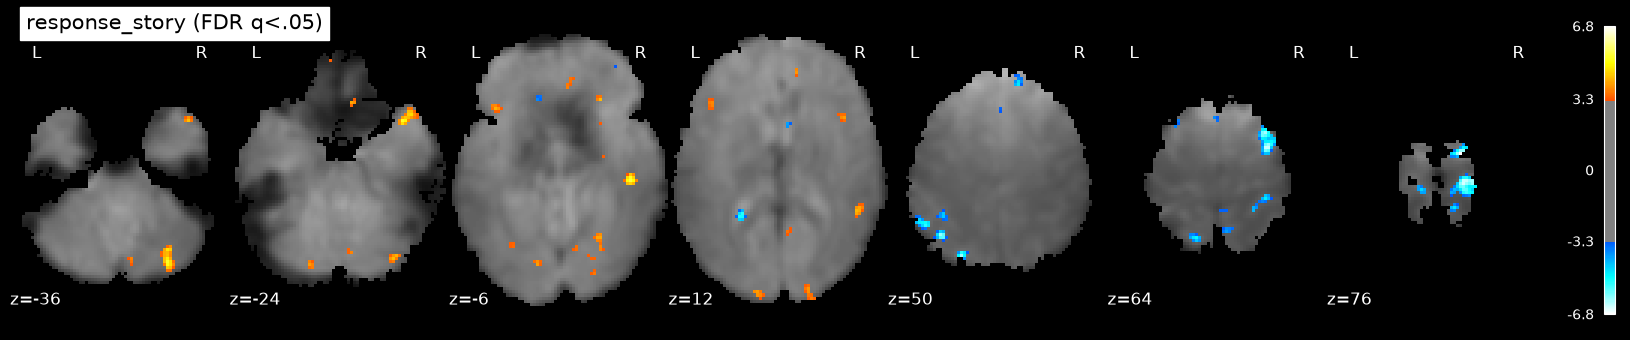

In [18]:
from nilearn.plotting import plot_stat_map
from nilearn.image import mean_img

mean_img_ = mean_img(FMRI_SMOOTH)

for name, img in thresholded.items():
    plotting.plot_stat_map(img, bg_img=mean_img_, threshold=thr[name],
                           display_mode="z", cut_coords=None, # None, automatically choose cut
                           title=f"{name} (FDR q<.05)", colorbar=True)
    # saving images 
    plt.savefig(op.join(GLM_FIG_DIR, f"{name}_zmap.png"), dpi=300, bbox_inches="tight")



Every statistical maps except ‘cue’ contains negative clusters at the very top of the brain, this might be due to edge artifacts and not deactivation during these events. 

* Cue: important clusters at the left and right superior temporal gyrus (STG), which is involved in the processing of auditory information. Bigger cluster on the right STG. Clusters at STG are also found in present and question regressors for both math and story. Expected for an auditory task.

* Math-related regressors: clusters at the left intraparietal sulcus (IPS), which is involved in numerical processing. Clusters in the frontal lobe in the event of present math.

* Story-related regressors: clear activation in the occipital region. 

* Question regressors: cluster at the angular gyrus for both math and story question regressors


### 1.3.d Contrast vector and story-vs-math activation map
We are interested in the *difference* between story and math events. To investigate the overall differences, we can define a contrast vector with +1 for every language specific regressors and a -1 for every math specific regressors. Every other unrelated regressors (motion counfounds, drifts) are set to 0. We would get :

$$\large c_{story - math} =
\begin{bmatrix}
0 & -1 & 1 & -1 & 1 & -1 & 1 &0 &...\end{bmatrix}
\begin{bmatrix}
\vec{\beta_{cue}}\\
\vec{\beta_{present\_math}}\\
\vec{\beta_{present\_story}}\\
\vec{\beta_{question\_math}}\\
\vec{\beta_{question\_story}}\\
\vec{\beta_{response\_math}}\\
\vec{\beta_{response\_story}}\\
\vec{\beta_{rot\_x}}\\
\vec{...}\\
\end{bmatrix}$$
In such a set up, positive clusters would match with story activated regions whereas negative clusters would match with math activated regions.

In [19]:
# define story & math regressors
story_reg = ['present_story','question_story','response_story'] 
math_reg = ['present_math','question_math','response_math']

cols = list(design_matrix.columns)

story_vec = np.zeros(len(cols))
for r in story_reg:
    story_vec[cols.index(r)] = 1.0
math_vec = np.zeros(len(cols))
for r in math_reg:
    math_vec[cols.index(r)] = 1.0

story_minus_math = story_vec - math_vec
print('Contrast vector: ',story_minus_math)

Contrast vector:  [ 0. -1.  1. -1.  1. -1.  1.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]


In [20]:
z_map = fmri_glm.compute_contrast(story_minus_math, output_type='z_score')

thresholded_sto_min_mat, thr_sto_min_math = threshold_stats_img(z_map, alpha=0.05, 
                                                             height_control="fdr", cluster_threshold=10)
    
# saving to csv file
table = get_clusters_table(z_map, stat_threshold=thr_sto_min_math, cluster_threshold=10, two_sided=True)
table.to_csv(op.join(STAT_DIR, f"story_minus_math_clusters.csv"), index=False)

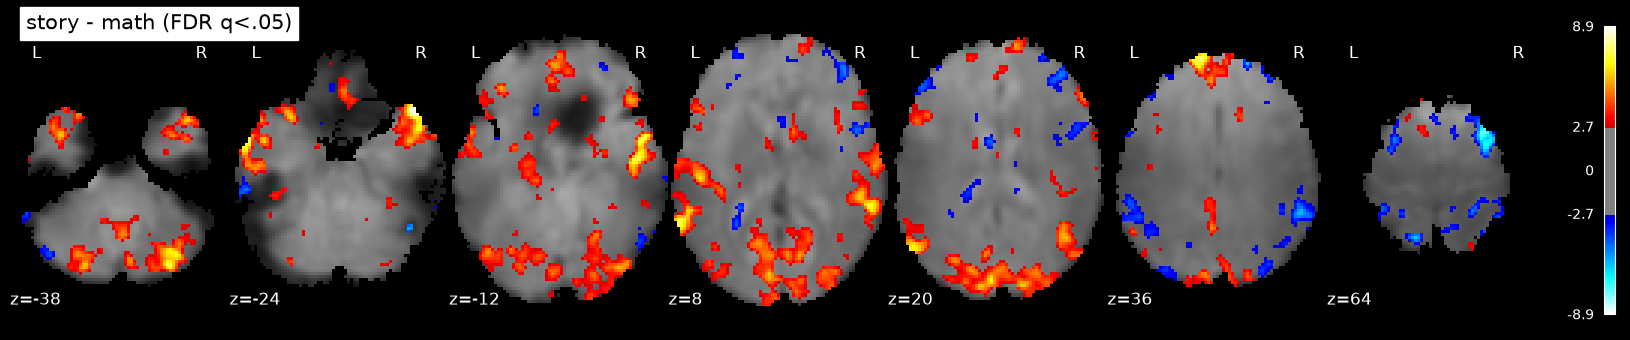

In [21]:
mean_img_ = mean_img(FMRI_SMOOTH)

plotting.plot_stat_map(thresholded_sto_min_mat, bg_img=mean_img_, threshold=thr_sto_min_math,
                           display_mode="z", cut_coords=None,
                           title=f"story - math (FDR q<.05)", colorbar=True)
# saving image 
plt.savefig(op.join(GLM_FIG_DIR, f"story_minus_math_zmap.png"), dpi=300, bbox_inches="tight")

### 1.3.e Networks more involved in numerical than semantic

Let us use a similar figure as before but in an interactive way to enable the navigation through the voxels


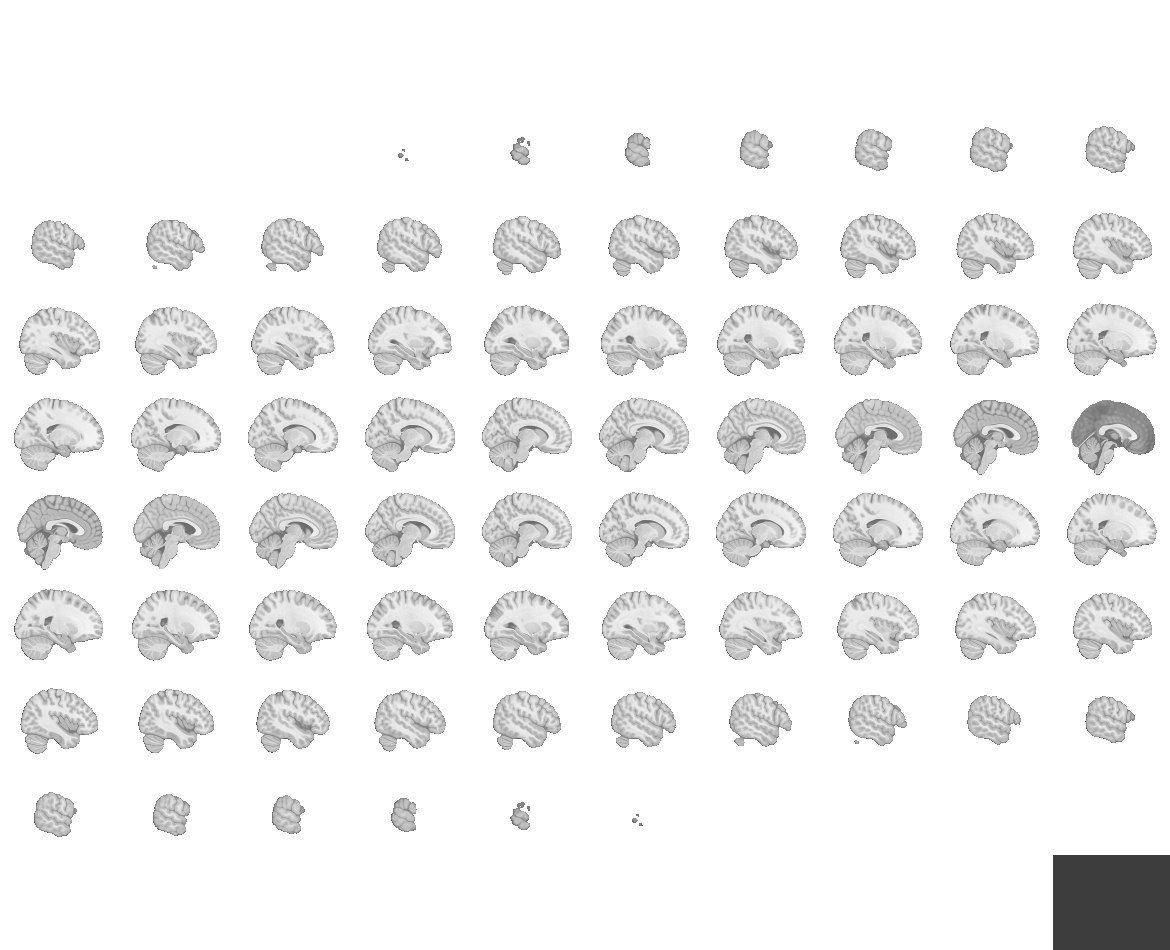
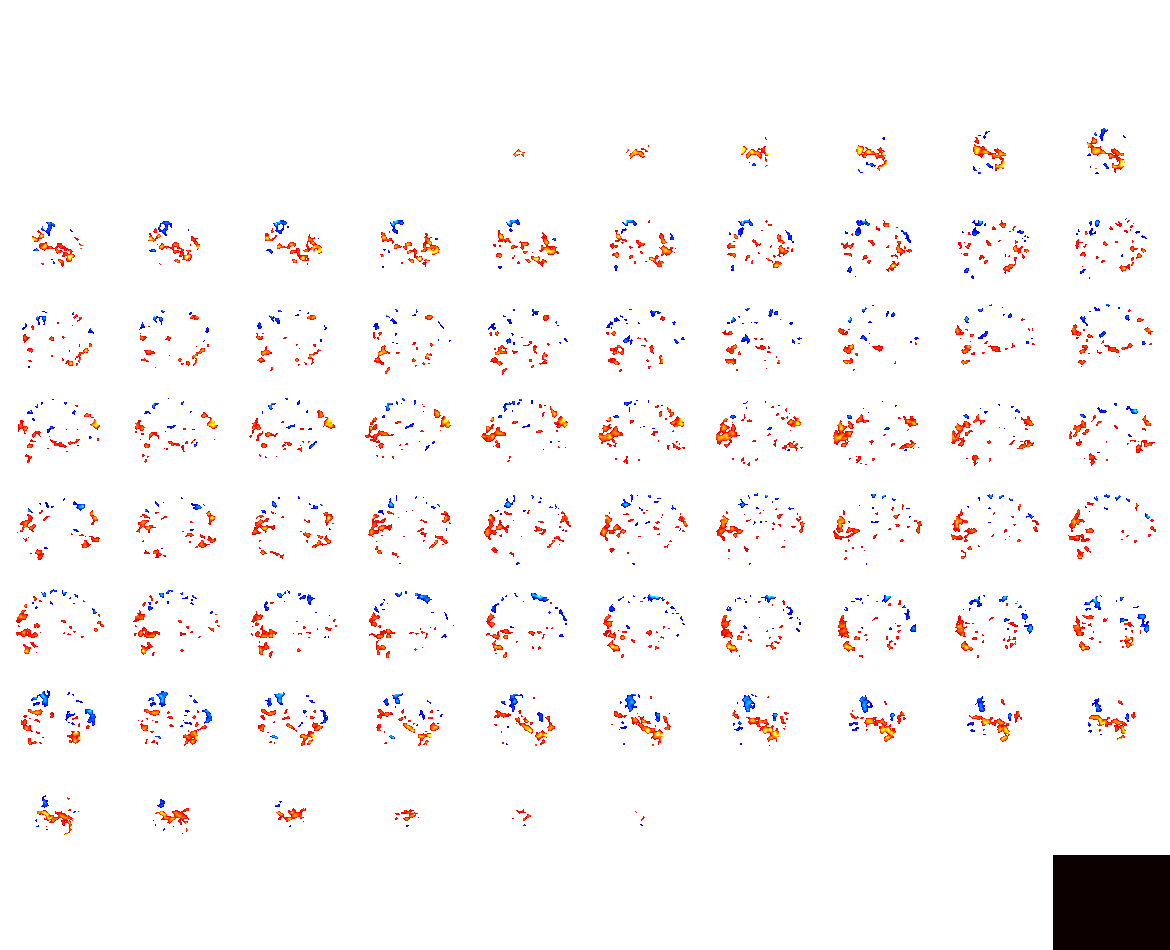

In [22]:

view = plotting.view_img(thresholded_sto_min_mat, threshold=thr_sto_min_math, cut_coords=None, 
                          colorbar=True, title="story - math (FDR q<.05)", symmetric_cmap=True,  black_bg=False)   
view.save_as_html(op.join(FIG_DIR, "story_minus_math_zmap.html"))

view 


Here we give to each cluster peak a label coirresponding to the brain region they are in (according to the harvard-oxford altlas)

In [23]:
from nilearn import datasets

ho = datasets.fetch_atlas_harvard_oxford("cort-maxprob-thr25-2mm")   # cortical regions
hos = datasets.fetch_atlas_harvard_oxford("sub-maxprob-thr25-2mm")   # subcortical regions


def region_at(xyz, atlas=ho):
    img = atlas.maps
    ijk = np.round(np.linalg.inv(img.affine) @ np.append(xyz, 1))[:3].astype(int)
    if np.any(ijk < 0) or np.any(ijk >= img.shape):
        return "outside atlas"
    return atlas.labels[int(np.asarray(img.dataobj)[tuple(ijk)])]

table = get_clusters_table(z_map, stat_threshold=thr_sto_min_math, cluster_threshold=10, two_sided=True)
table["region"] = [region_at((x, y, z)) for x, y, z in zip(table["X"], table["Y"], table["Z"])]

bg = table["region"] == "Background"
table.loc[bg, "region"] = [region_at((x, y, z), atlas=hos)
                           for x, y, z in zip(table.loc[bg, "X"], table.loc[bg, "Y"], table.loc[bg, "Z"])]


table.to_csv(op.join(STAT_DIR, f"story_minus_math_clusters_region.csv"), index=False)


Added README.md to /home/jovyan/nilearn_data


Dataset created in /home/jovyan/nilearn_data/fsl



Downloaded 13475736 of 25716861 bytes (52.4%,    0.9s remaining) ...done. (2 seconds, 0 min)
Extracting data from /home/jovyan/nilearn_data/fsl/c4d84bbdf5c3325f23e304cdea1e9706/HarvardOxford.tgz..... done.


In [24]:
math_brain_regions = table[table["Peak Stat"] < 0]["region"]
story_brain_regions = table[table["Peak Stat"] > 0]["region"] 

In [25]:
print("Regions where dominating math activity appear:")
math_brain_regions.unique()

Regions where dominating math activity appear:


<StringArray>
[                          'Middle Frontal Gyrus',
                          'Right Cerebral Cortex',
                         'Superior Frontal Gyrus',
    'Lateral Occipital Cortex, superior division',
                                     'Background',
                                  'Angular Gyrus',
        'Supramarginal Gyrus, posterior division',
                       'Superior Parietal Lobule',
                                   'Frontal Pole',
                              'Precuneous Cortex',
       'Inferior Frontal Gyrus, pars opercularis',
                       'Central Opercular Cortex',
                               'Precentral Gyrus',
   'Middle Temporal Gyrus, temporooccipital part',
                         'Left Lateral Ventricle',
    'Inferior Temporal Gyrus, posterior division',
                           'Left Cerebral Cortex',
                     'Left Cerebral White Matter',
    'Lateral Occipital Cortex, inferior division',
                 

In [26]:
print("Regions only dominated by math activity :")
math_brain_regions[~math_brain_regions.isin(story_brain_regions)].unique()

Regions only dominated by math activity :


<StringArray>
[                               'Angular Gyrus',
      'Supramarginal Gyrus, posterior division',
     'Inferior Frontal Gyrus, pars opercularis',
 'Middle Temporal Gyrus, temporooccipital part',
                       'Left Lateral Ventricle',
    'Middle Temporal Gyrus, posterior division',
                               'Insular Cortex']
Length: 7, dtype: str

In [27]:
print("Regions where dominating story activity appear:")
story_brain_regions.unique()

Regions where dominating story activity appear:


<StringArray>
[                                 'Temporal Pole',
    'Superior Temporal Gyrus, posterior division',
       'Middle Temporal Gyrus, anterior division',
                           'Left Cerebral Cortex',
                                   'Frontal Pole',
                         'Superior Frontal Gyrus',
                                     'Background',
                                 'Occipital Pole',
                          'Intracalcarine Cortex',
                       'Occipital Fusiform Gyrus',
      'Inferior Frontal Gyrus, pars triangularis',
                          'Right Cerebral Cortex',
                          'Frontal Medial Cortex',
                    'Right Cerebral White Matter',
                           'Middle Frontal Gyrus',
                               'Precentral Gyrus',
                              'Precuneous Cortex',
            'Cingulate Gyrus, posterior division',
   'Temporal Fusiform Cortex, posterior division',
                 

In [28]:
print("Regions only dominated by story activity :")
story_brain_regions[~story_brain_regions.isin(math_brain_regions)].unique()

Regions only dominated by story activity :


<StringArray>
[                               'Temporal Pole',
  'Superior Temporal Gyrus, posterior division',
     'Middle Temporal Gyrus, anterior division',
                               'Occipital Pole',
                        'Intracalcarine Cortex',
                     'Occipital Fusiform Gyrus',
    'Inferior Frontal Gyrus, pars triangularis',
          'Cingulate Gyrus, posterior division',
 'Temporal Fusiform Cortex, posterior division',
                              'Right Accumbens',
                                'Right Caudate',
                                'Right Putamen',
                                 'Left Caudate',
                                'Left Thalamus',
                                'Left Amygdala',
                                 'Left Putamen',
                       'Frontal Orbital Cortex',
                                   'Brain-Stem',
           'Cingulate Gyrus, anterior division',
    'Parahippocampal Gyrus, posterior division',
      

In [29]:
ZMAP = thresholded_sto_min_mat # story - math z-map, zero outside significant voxels
z_img = image.load_img(ZMAP)
z = z_img.get_fdata()
vox_ml = float(np.prod(z_img.header.get_zooms()[:3])) / 1000.0     # volume of one voxel (mL)

def label_volume(atlas):
    img = image.resample_to_img(atlas.maps, z_img, interpolation="nearest")
    return np.rint(img.get_fdata()).astype(int), list(atlas.labels)

lab_c, names_c = label_volume(ho)
lab_s, names_s = label_volume(hos)

# one row per active voxel 
act = z != 0
ijk = np.argwhere(act) # same (C) order as z[act]
x_mm = nib.affines.apply_affine(z_img.affine, ijk)[:, 0]
hemi = np.where(x_mm < 0, "L", "R")

cort = np.array([names_c[i] for i in lab_c[act]])
subc = np.array([names_s[i] for i in lab_s[act]])
region = np.where(lab_c[act] > 0, cort, # cortical atlas first
         np.where(lab_s[act] > 0, subc, # subcortical / WM / ventricle
                  "outside atlases (e.g. cerebellum)"))

df = pd.DataFrame({"region": region, "hemi": hemi, "z": z[act]})

# signed summary per region and hemisphere 
res = (df.groupby(["region", "hemi"]).agg(
        story_ml=("z", lambda s: (s > 0).sum() * vox_ml), # volume with story > math
        math_ml =("z", lambda s: (s < 0).sum() * vox_ml), # volume with math > story
        sum_z   =("z", "sum"), # signed total activation
        mean_z  =("z", "mean"),
        peak_z  =("z", lambda s: s.loc[s.abs().idxmax()]))
       .reset_index())
res["net_ml"] = res.story_ml - res.math_ml # > 0: story, < 0: math
res["label"]  = res.region + " (" + res.hemi + ")"
res = res.sort_values("sum_z")
res.round(2).to_csv("region_activation_story_minus_math.csv", index=False)
res.round(2)


,region,hemi,story_ml,math_ml,sum_z,mean_z,peak_z,net_ml,label
110,"Supramarginal Gyrus, posterior division",R,0.70,4.22,-1827.04,-2.97,6.91,-3.52,"Supramarginal Gyrus, posterior division (R)"
99,Superior Parietal Lobule,L,0.00,2.30,-1056.57,-3.68,-6.33,-2.30,Superior Parietal Lobule (L)
100,Superior Parietal Lobule,R,0.10,2.05,-1003.92,-3.75,-6.69,-1.95,Superior Parietal Lobule (R)
1,Angular Gyrus,R,1.00,3.03,-1003.14,-1.99,6.68,-2.03,Angular Gyrus (R)
58,Middle Frontal Gyrus,R,0.50,2.28,-947.99,-2.72,-7.76,-1.78,Middle Frontal Gyrus (R)
...,...,...,...,...,...,...,...,...,...
90,Right Cerebral White Matter,R,7.91,1.43,2779.66,2.38,6.16,6.48,Right Cerebral White Matter (R)
67,Occipital Pole,L,6.59,0.04,3235.59,3.90,6.74,6.55,Occipital Pole (L)
118,Temporal Pole,R,6.77,0.00,3663.82,4.33,8.87,6.77,Temporal Pole (R)
68,Occipital Pole,R,10.58,0.00,4958.71,3.75,6.13,10.58,Occipital Pole (R)


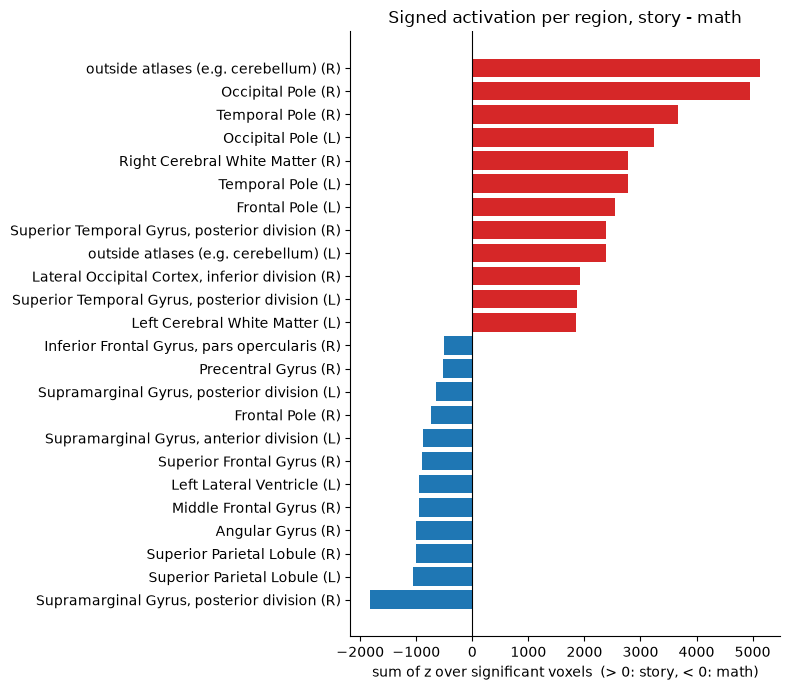

In [30]:
top = pd.concat([res.head(12), res.tail(12)]) # most negative (math) and most positive (story)
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(top.label, top.sum_z, color=np.where(top.sum_z > 0, "#d62728", "#1f77b4"))
ax.axvline(0, color="k", lw=0.8)
ax.set(xlabel="sum of z over significant voxels  (> 0: story, < 0: math)",
       title="Signed activation per region, story - math")
ax.spines[["top", "right"]].set_visible(False)
plt.savefig(op.join(FIG_DIR, f"story_vs_math_per_region.png"), dpi=300, bbox_inches="tight")
fig.tight_layout()

- Story > Math (Semantic Processing):

This activation contrast is high in the following regions : the temporal poles (the tip of the temporal lobe), the occipital pole (back of the head), the inferior frontal gyrus (IFG) (including pars triangularis), and deep/limbic structures like the left amygdala and thalamus, the middle temporal gyrus (MTG) (anterior division) and the superior temporal gyrus (STG) (posterior division) which includes Wernicke’s area known to be responsible for understanding and comprehending spoken and written language.

These structures map onto the primary Language Network, auditory-visual integration pathways, and limbic circuits, mediating semantic processing, narrative comprehension, and conceptual integration.

- Math > Story (Numerical Processing)

The regions uniquely or predominantly activated by the math task include the angular gyrus, supramarginal gyrus (posterior division), inferior Frontal gyrus (pars opercularis), superior parietal lobule, and middle frontal gyrus.

These regions map onto the Frontoparietal Control Network (Central Executive Network) and the Dorsal Attention Network, which drive tasks and decision making, goal-directed calculation, working memory, and attentional allocation.

Now let's analyse the yeo functional networks atlas and determine in which networks each activation (story vs math) dominates.

In [31]:
import nibabel as nib

sch = datasets.fetch_atlas_schaefer_2018(n_rois=400, yeo_networks=7, resolution_mm=2)

names = [l.decode() if isinstance(l, bytes) else str(l) for l in sch.labels]
if names[0].lower() == "background":  
    names = names[1:]

NET_OF = {"Vis": 1, "SomMot": 2, "DorsAttn": 3, "SalVentAttn": 4, "Limbic": 5, "Cont": 6, "Default": 7}
YEO7   = {1: "Visual", 2: "Somatomotor", 3: "Dorsal attention", 4: "Ventral attention / salience",
          5: "Limbic", 6: "Frontoparietal control", 7: "Default"}

lut = np.zeros(len(names) + 1, dtype=int) # parcel value -> Yeo network (0 = none)
for i, n in enumerate(names, start=1):
    for key, k in NET_OF.items():
        if f"_{key}_" in n:
            lut[i] = k

parc  = np.rint(image.resample_to_img(sch.maps, z_img, interpolation="nearest").get_fdata()).astype(int)
net   = lut[parc]
brain = np.asarray(nib.load(FUNC_MASK).dataobj) > 0

print(pd.Series(net[brain]).value_counts().sort_index())

rows = []
for k, name in YEO7.items():
    m = (net == k) & brain
    rows.append({"network": name,
                 "story_ml": ((z > 0) & m).sum() * vox_ml,
                 "math_ml":  ((z < 0) & m).sum() * vox_ml,
                 "net_ml":   (((z > 0) & m).sum() - ((z < 0) & m).sum()) * vox_ml, # > 0 story, < 0 math
                 "% of network, story": 100 * ((z > 0) & m).sum() / m.sum(),
                 "% of network, math":  100 * ((z < 0) & m).sum() / m.sum()})
pd.DataFrame(rows).round(1)


Dataset created in /home/jovyan/nilearn_data/schaefer_2018



 ...done. (0 seconds, 0 min)
 ...done. (0 seconds, 0 min)


0    100996
1     22243
2     17881
3     13073
4     13762
5     10767
6     17573
7     31138
Name: count, dtype: int64


,network,story_ml,math_ml,net_ml,"% of network, story","% of network, math"
0,Visual,54.9,2.5,52.4,30.9,1.4
1,Somatomotor,13.1,4.6,8.6,9.2,3.2
2,Dorsal attention,4.6,12.3,-7.7,4.4,11.8
3,Ventral attention / salience,5.5,6.2,-0.8,5.0,5.7
4,Limbic,9.8,0.5,9.3,11.4,0.6
5,Frontoparietal control,5.0,20.0,-15.0,3.6,14.2
6,Default,58.2,8.4,49.8,23.4,3.4


In [32]:
rows = []
for k, nname in YEO7.items():
    m = (net == k) & brain
    tot = m.sum()
    for rid in np.unique(lab_c[m]):
        if rid == 0:                                   # skip voxels with no cortical region label
            continue
        r = m & (lab_c == rid)
        rows.append({"id": k, "network": nname, "region": names_c[rid],
                     "region_in_network_ml": r.sum() * vox_ml,
                     "% of network": 100 * r.sum() / tot,
                     "story_ml": ((z > 0) & r).sum() * vox_ml,
                     "math_ml":  ((z < 0) & r).sum() * vox_ml})

net_reg = pd.DataFrame(rows)
net_reg["net_ml"] = net_reg.story_ml - net_reg.math_ml            # > 0 story, < 0 math
net_reg = net_reg.sort_values(["id", "% of network"], ascending=[True, False]).drop(columns="id")

# Compact list: the 8 main regions of each network
for nname, g in net_reg.groupby("network", sort=False):
    print(f"{nname}: " + ", ".join(f"{r} ({p:.0f}%)" for r, p in zip(g.region.head(8), g["% of network"].head(8))))

net_reg.round(1)                                                  # full table

Visual: Occipital Pole (20%), Lateral Occipital Cortex, inferior division (14%), Lingual Gyrus (13%), Lateral Occipital Cortex, superior division (11%), Occipital Fusiform Gyrus (7%), Intracalcarine Cortex (6%), Cuneal Cortex (5%), Temporal Occipital Fusiform Cortex (5%)
Somatomotor: Precentral Gyrus (28%), Postcentral Gyrus (26%), Central Opercular Cortex (7%), Planum Temporale (5%), Superior Temporal Gyrus, posterior division (4%), Heschl's Gyrus (includes H1 and H2) (3%), Juxtapositional Lobule Cortex (formerly Supplementary Motor Cortex) (3%), Parietal Opercular Cortex (3%)
Dorsal attention: Lateral Occipital Cortex, superior division (21%), Superior Parietal Lobule (13%), Precentral Gyrus (10%), Inferior Temporal Gyrus, temporooccipital part (7%), Precuneous Cortex (6%), Middle Temporal Gyrus, temporooccipital part (5%), Postcentral Gyrus (5%), Superior Frontal Gyrus (5%)
Ventral attention / salience: Insular Cortex (11%), Frontal Pole (8%), Cingulate Gyrus, anterior division (7%)

,network,region,region_in_network_ml,% of network,story_ml,math_ml,net_ml
15,Visual,Occipital Pole,35.3,19.8,16.4,0.0,16.3
3,Visual,"Lateral Occipital Cortex, inferior division",25.8,14.5,6.9,0.5,6.4
10,Visual,Lingual Gyrus,23.7,13.3,3.8,0.0,3.8
2,Visual,"Lateral Occipital Cortex, superior division",19.5,11.0,5.1,1.5,3.5
13,Visual,Occipital Fusiform Gyrus,12.7,7.2,6.5,0.0,6.5
...,...,...,...,...,...,...,...
141,Default,"Lateral Occipital Cortex, inferior division",0.2,0.1,0.1,0.0,0.1
123,Default,Insular Cortex,0.1,0.1,0.1,0.0,0.1
153,Default,Planum Temporale,0.1,0.0,0.0,0.0,0.0
154,Default,Supracalcarine Cortex,0.1,0.0,0.0,0.0,0.0


In [38]:
import re
import numpy as np, pandas as pd, nibabel as nib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from IPython.display import display, HTML
from nilearn import plotting

BG = mean_img_                               # or: datasets.load_mni152_template(resolution=2)

YEO_COLORS = ["#781286", "#4682B4", "#00760E", "#C43AFA", "#DCF8A4", "#E69422", "#CD3E4E"]
cmap = ListedColormap(YEO_COLORS)

# network-level summary, including voxels outside the cortical networks (cerebellum, subcortex, white matter)
NET_NAMES = {**YEO7, 0: "Outside cortical networks"}
rows = []
for k, nname in NET_NAMES.items():
    m = (net == k) & brain
    rows.append({"k": k, "network": nname,
                 "story_ml":  ((z > 0) & m).sum() * vox_ml,
                 "math_ml":   ((z < 0) & m).sum() * vox_ml,
                 "story_pct": 100 * ((z > 0) & m).sum() / m.sum(),
                 "math_pct":  100 * ((z < 0) & m).sum() / m.sum()})
ov = pd.DataFrame(rows)
ov["net_ml"] = ov.story_ml - ov.math_ml                 # > 0: story, < 0: math
ov.round(1)

# HTML legend (colour -> network name)
LEGEND = ("<div style='font:13px sans-serif;margin:6px 0'>" +
          "".join(f"<span style='display:inline-block;width:12px;height:12px;background:{c};"
                  f"border:1px solid #555;margin:0 4px 0 12px'></span>{k}. {n}"
                  for k, (c, n) in enumerate(zip(YEO_COLORS, YEO7.values()), start=1)) + "</div>")


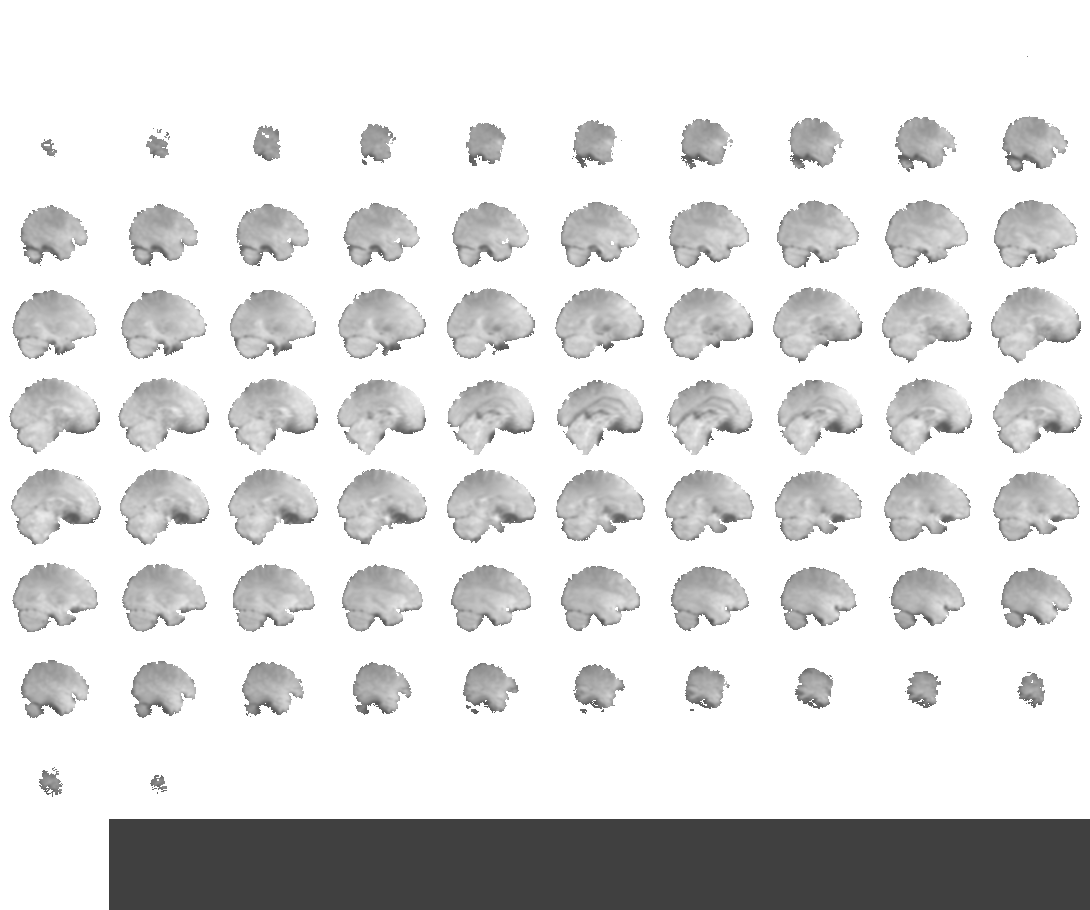
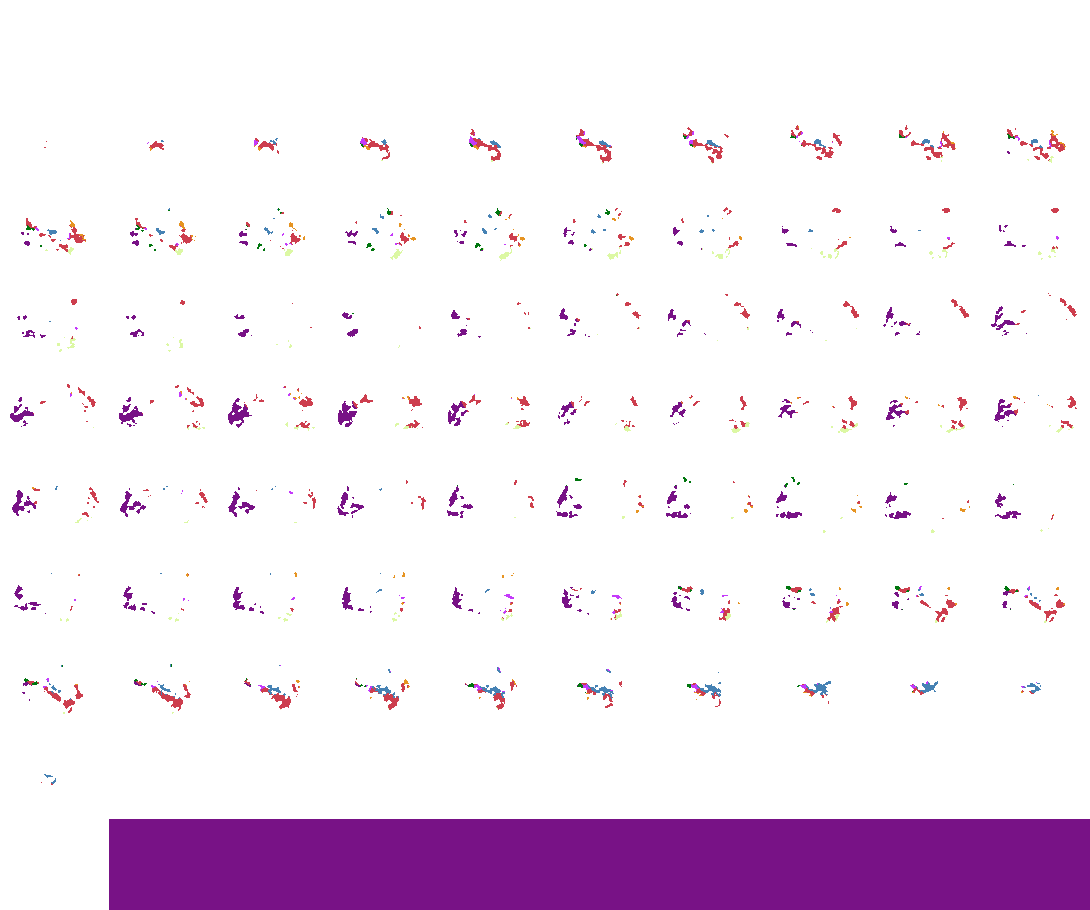


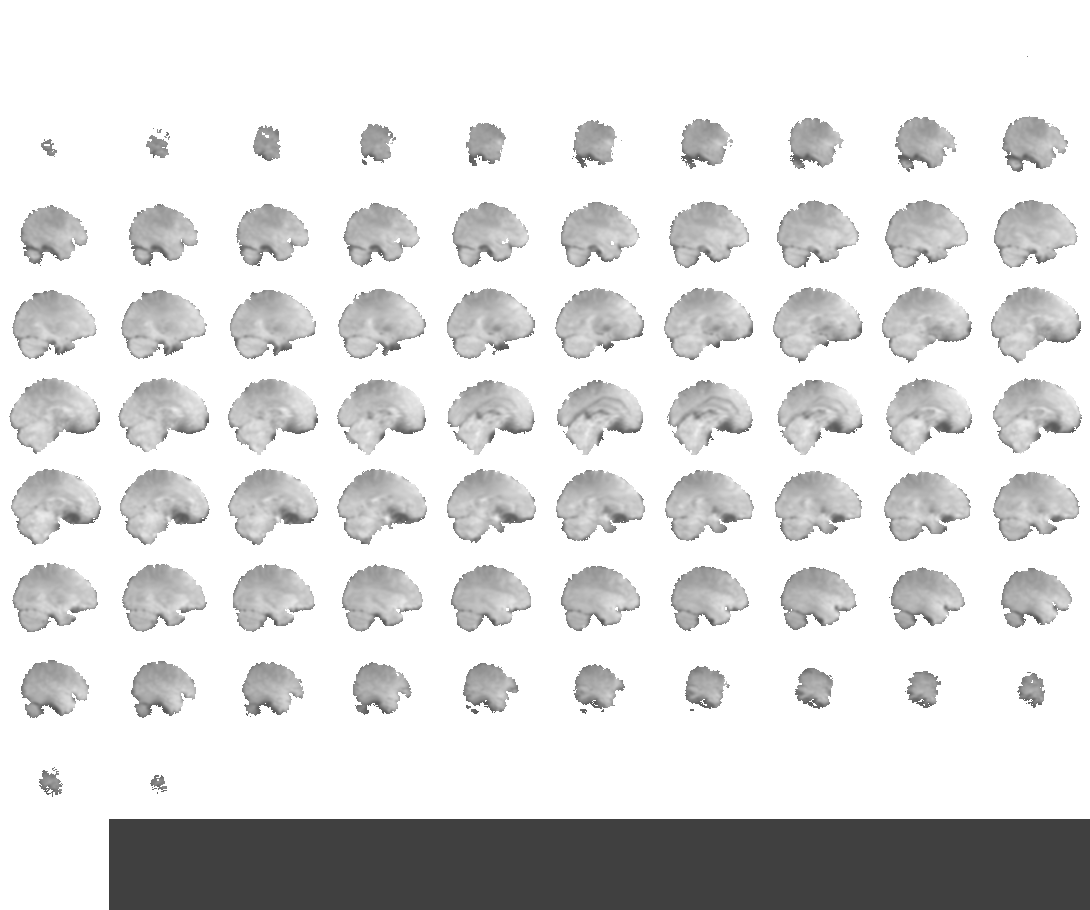
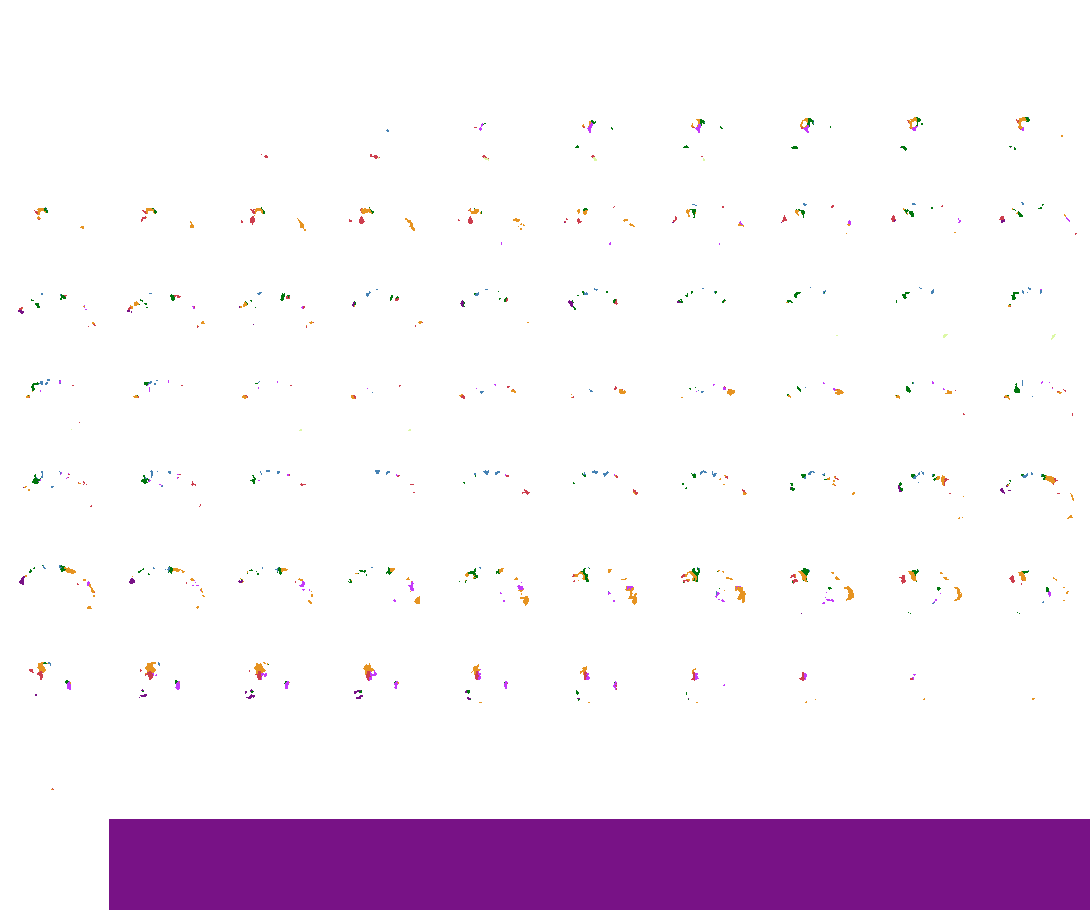

In [39]:
def networks_on_activation(sign):
    lab = np.where(z * sign > 0, net, 0).astype(np.int16)         # network id only where active
    return nib.Nifti1Image(lab, z_img.affine)

for sign, title in [(+1, "story > math, coloured by network"), (-1, "math > story, coloured by network")]:
    view = plotting.view_img(networks_on_activation(sign), bg_img=BG, cmap=cmap, vmin=1, vmax=7,
                             symmetric_cmap=False, threshold=0.5, resampling_interpolation="nearest",
                             colorbar=False, black_bg=False, title=title)
    display(HTML(LEGEND))        # legend above the viewer
    display(view)

# Optional: a standalone HTML file with the legend built in
# html = re.sub(r"(<body[^>]*>)", lambda m: m.group(1) + LEGEND, view.get_standalone(), count=1)
# open(op.join(GLM_FIG_DIR, "networks_math_gt_story.html"), "w").write(html)

saved /data/Desktop/myfiles/NSSP/Project_1/NSSP_projects/figures/GLM/story_minus_math_with_yeo_outlines.png


'/data/Desktop/myfiles/NSSP/Project_1/NSSP_projects/figures/GLM/story_minus_math_with_yeo_outlines.png'

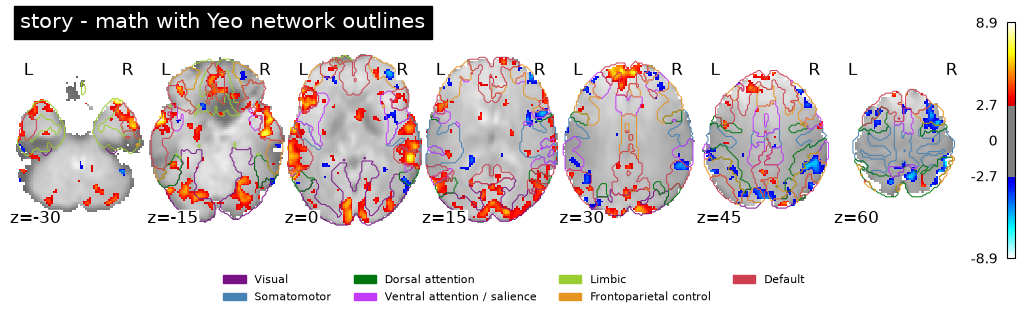

In [45]:
CONTOUR = ["#781286", "#4682B4", "#00760E", "#C43AFA", "#9ACD32", "#E69422", "#CD3E4E"]   # darker limbic
fig, ax = plt.subplots(figsize=(13, 3.4))
disp = plotting.plot_stat_map(z_img, bg_img=mean_img_, threshold=thr_sto_min_math, display_mode="z",
                              cut_coords=[-30, -15, 0, 15, 30, 45, 60], axes=ax, colorbar=True,
                              black_bg=False, title="story - math with Yeo network outlines")
for k, col in zip(range(1, 8), CONTOUR):
    disp.add_contours(nib.Nifti1Image((net == k).astype(np.int16), z_img.affine),
                      levels=[0.5], colors=[col], linewidths=0.7)
ax.figure.legend(handles=[Patch(color=c, label=n) for c, n in zip(CONTOUR, YEO7.values())],
                 loc="lower center", ncol=4, frameon=False, fontsize=8)
save_fig(fig, GLM_FIG_DIR, "story_minus_math_with_yeo_outlines")

saved /data/Desktop/myfiles/NSSP/Project_1/NSSP_projects/figures/GLM/story_math_per_network.png


'/data/Desktop/myfiles/NSSP/Project_1/NSSP_projects/figures/GLM/story_math_per_network.png'

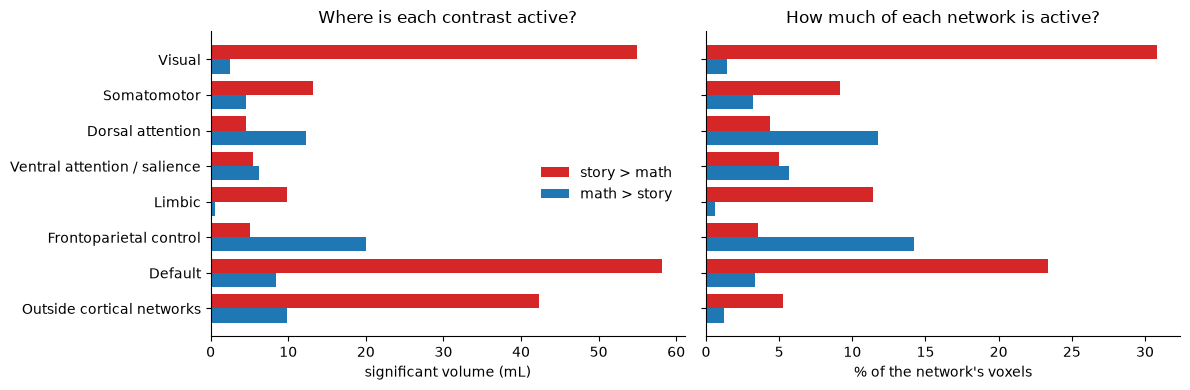

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
y = np.arange(len(ov))
for ax, a, b, xl, t in [(axes[0], "story_ml", "math_ml", "significant volume (mL)", "Where is each contrast active?"),
                        (axes[1], "story_pct", "math_pct", "% of the network's voxels", "How much of each network is active?")]:
    ax.barh(y - 0.2, ov[a], 0.4, color="#d62728", label="story > math")
    ax.barh(y + 0.2, ov[b], 0.4, color="#1f77b4", label="math > story")
    ax.set(xlabel=xl, title=t); ax.spines[["top", "right"]].set_visible(False)
axes[0].set_yticks(y); axes[0].set_yticklabels(ov.network); axes[0].invert_yaxis()
axes[0].legend(frameon=False)
fig.tight_layout()
save_fig(fig, GLM_FIG_DIR, "story_math_per_network")

saved /data/Desktop/myfiles/NSSP/Project_1/NSSP_projects/figures/GLM/story_math_regions_per_network.png


'/data/Desktop/myfiles/NSSP/Project_1/NSSP_projects/figures/GLM/story_math_regions_per_network.png'

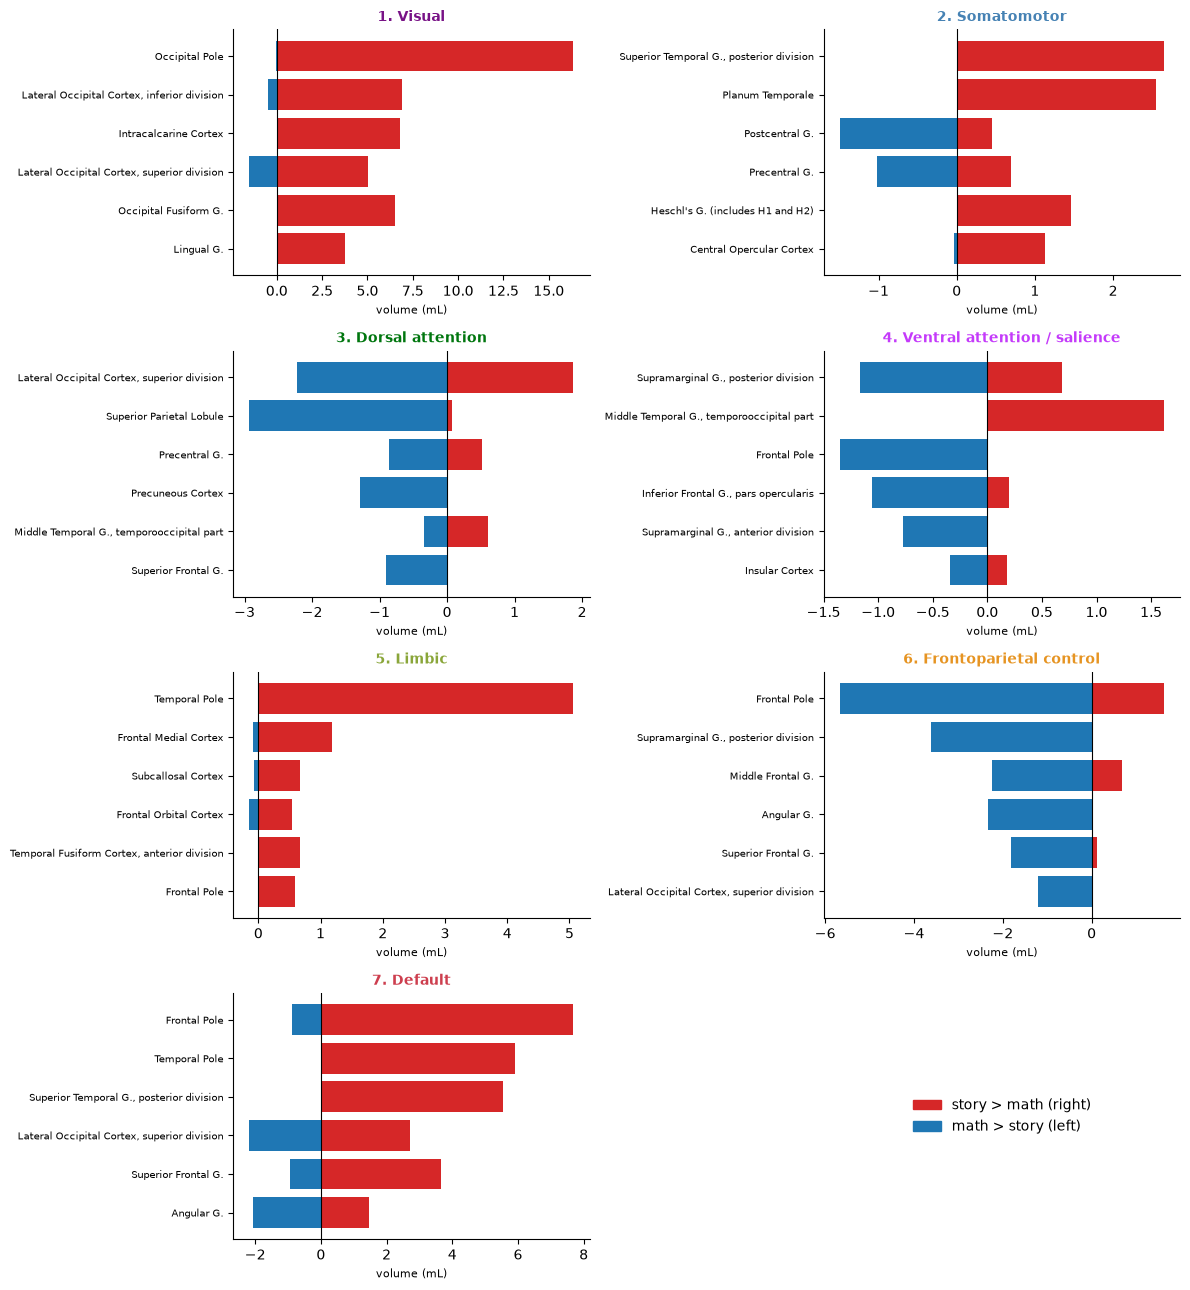

In [41]:
fig, axes = plt.subplots(4, 2, figsize=(12, 13))
for ax, (k, nname) in zip(axes.ravel(), YEO7.items()):
    g = net_reg[net_reg.network == nname].copy()
    g["total"] = g.story_ml + g.math_ml
    g = g[g.total > 0].sort_values("total", ascending=False).head(6).iloc[::-1]
    short = g.region.str.replace(", division", "", regex=False).str.replace("Gyrus", "G.", regex=False)
    ax.barh(short, g.story_ml, color="#d62728")
    ax.barh(short, -g.math_ml, color="#1f77b4")
    ax.axvline(0, color="k", lw=0.8)
    ax.set_title(f"{k}. {nname}", color=YEO_COLORS[k - 1] if k != 5 else "#8aa63a", fontsize=10, fontweight="bold")
    ax.tick_params(axis="y", labelsize=7); ax.spines[["top", "right"]].set_visible(False)
    ax.set_xlabel("volume (mL)", fontsize=8)
last = axes.ravel()[-1]; last.axis("off")
last.legend(handles=[Patch(color="#d62728", label="story > math (right)"),
                     Patch(color="#1f77b4", label="math > story (left)")], loc="center", frameon=False)
fig.tight_layout()
save_fig(fig, GLM_FIG_DIR, "story_math_regions_per_network")

### 1.3.f semantic language processing regions 

According to the literature on the neurobiology of language (e.g., Binder et al., 2011), core regions dedicated to semantic processing and conceptual retrieval include: the anterior temporal lobe (ATL) (a critical hub for semantic integration), the middle temporal gyrus (MTG) and inferior temporal gyrus (ITG).

In comparison with the observed results (Story > Math), the key semantic regions stand out as clearly activated. We observe strong, continuous activation along the temporal cortex, extending into the middle temporal gyrus and reaching into the anterior temporal lobe (ATL), as well as clusters in the left inferior frontal gyrus.

Our observed activations align with the canonical semantic network established in the literature.

Although the story blocks were presented auditorily, the contrast maps reveal significant activation in early visual and occipital structures (ex. the occipital pole). This reflects the engagement of visual mental imagery during narrative comprehension, as listeners spontaneously construct mental visual models of the unfolding story plot a process far more prominent during narrative listening than during rule-based arithmetic calculation.

### Outputs of 1.3 reused in Part 2

| Variable | File | Used for |
|---|---|---|
| `DESIGN_MAT` | `derivatives/glm/design_matrix.csv` | regressors of design matrix, used for correlation with PCA |